# FlashAttention-2 from scratch: loop swap, deferred rescaling and work partitioning

*Notebook 2 of 6. Prerequisite: notebook 1 (tiling, online softmax). We re-define everything we use so this notebook runs on its own.*

**TL;DR.** FlashAttention-1 made attention memory-efficient but left the GPU under-used: the paper (Dao, 2023, [arXiv:2307.08691](https://arxiv.org/abs/2307.08691)) *reports* reaching only 25-40% of A100 peak FLOP/s, and FlashAttention-2 *reports* 50-73%, roughly 2x faster than FA-1 (reported, not measured here). FA-2 changes three things and none of them changes the output: (1) it does fewer non-matmul operations, (2) it makes the sequence length a parallel dimension by swapping the loops, and (3) it splits the work inside a thread block so that warps do not have to talk to each other. We implement each change, verify the output is still exact, and measure what we can on a CPU: operation counts, memory-traffic counts and a scheduling model of SM occupancy. The measured summary is in the final section.

**Honest scope.** Speed on a GPU depends on things this notebook cannot see (register pressure, shared-memory bank conflicts, instruction issue). Our occupancy and shared-memory figures are *models* built from stated counting rules, and each is labelled as such.

**Contents**
1. Recap: the FA-1 forward pass
2. Fewer non-matmul operations
3. Swapping the loops
4. Parallelism over the sequence
5. Causal masking: skipping tiles and balancing work
6. Splitting work between warps
7. The backward pass
8. What we tried that did not work
9. Closing thoughts

In [1]:
import math, numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from fa_kit import *
torch.manual_seed(0); print('device:', DEVICE)
HEADLINE = {}

device: cpu


## 1. Recap: the FA-1 forward pass

The only fact from notebook 1 we need is the online-softmax recurrence. For a row with running state $(m,\ell,o)$ and a new tile with scores $s$ and values $V_j$:

$$m'=\max(m,\max s),\quad \ell'=e^{m-m'}\ell+\sum e^{s-m'},\quad o'=\frac{\ell\,e^{m-m'}o+e^{s-m'}V_j}{\ell'} .$$

FA-1 loops over K/V blocks on the outside, so it must keep the *normalised* $o$ in HBM and re-read it for each block. We re-implement it here with the same op-counting rule as notebook 1 so that numbers are comparable.

**Counting rule (used throughout).** Per tile: 2 element ops per score for scale and row-max, 2 for exp and row-sum, plus 4 per row for the $(m,\ell)$ bookkeeping; FA-1 additionally spends 3 element ops per output element on the rescale ($\ell e^{m-m'}\cdot o$, $+$, $/\ell'$). Matmul FLOPs are $2\cdot$(product of dimensions). This is a model, not a profile.

In [2]:
def flash1_forward(q, k, v, Br, Bc, causal=False, io=None, fl=None):
    """FA-1: outer loop K/V blocks, inner loop Q blocks, O kept normalised in HBM."""
    N, d = q.shape; sc = 1 / math.sqrt(d); io = io or IOCounter(); fl = fl or FlopCounter()
    O = torch.zeros_like(q); l = torch.zeros(N, dtype=q.dtype); m = torch.full((N,), -float("inf"), dtype=q.dtype)
    for j in range(math.ceil(N / Bc)):
        js = slice(j*Bc, min((j+1)*Bc, N)); Kj, Vj = k[js], v[js]; io.read("K", Kj); io.read("V", Vj)
        for i in range(math.ceil(N / Br)):
            is_ = slice(i*Br, min((i+1)*Br, N))
            if causal and js.start > is_.stop - 1: continue
            Qi, Oi, li, mi = q[is_], O[is_], l[is_], m[is_]
            io.read("Q", Qi); io.read("O", Oi); io.read("l", li); io.read("m", mi)
            S = (Qi @ Kj.T) * sc; fl.mm(len(Qi), len(Kj), d); fl.elt(2 * S.numel())
            if causal:
                S = S.masked_fill(torch.arange(js.start, js.stop)[None] > torch.arange(is_.start, is_.stop)[:, None], -float("inf"))
            mn = torch.maximum(mi, S.max(1).values); ms = torch.where(torch.isinf(mn), torch.zeros_like(mn), mn)
            P = torch.exp(S - ms[:, None]); a = torch.exp(mi - ms); ln = a * li + P.sum(1); fl.elt(2 * S.numel() + 4 * len(Qi))
            On = ((a * li)[:, None] * Oi + P @ Vj) / ln[:, None]; fl.mm(len(Qi), d, len(Kj)); fl.elt(3 * Oi.numel())
            O[is_], l[is_], m[is_] = On, ln, mn; io.write("O", On); io.write("l", ln); io.write("m", mn)
    return O, m + torch.log(l)

Next, the first of FA-2's three changes, which is the cheapest to explain and the easiest to get subtly wrong.

## 2. Fewer non-matmul operations

**A tiny example.** Take the running state after two blocks from notebook 1: $m=4,\ \ell=1.5530,\ \tilde o=54.2410$ (scalar values). FA-1 would carry $o=\tilde o/\ell=34.93$ between blocks, dividing and re-multiplying by $\ell$ on every block. FA-2 carries the *unnormalised* $\tilde o$ and divides **once**, after the last block. The two routes give the same number; the second does fewer operations.

In [3]:
x = torch.tensor([1., 2., 3., 4.]); vv = torch.tensor([10., 20., 30., 40.])
def run(deferred):
    m, l, o = torch.tensor(-float("inf")), torch.tensor(0.), torch.tensor(0.); ops = 0
    for t in range(2):
        xb, vb_ = x[2*t:2*t+2], vv[2*t:2*t+2]; mn = torch.maximum(m, xb.max()); a = torch.exp(m - mn); p = torch.exp(xb - mn); ln = a*l + p.sum()
        if deferred: o = a*o + p @ vb_; ops += 1                      # 1 rescale op, no divide
        else:        o = (l*a*o + p @ vb_) / ln; ops += 3             # multiply by l*a, add, divide by l'
        m, l = mn, ln
    return (o / l if deferred else o).item(), ops
print("FA-1 style (normalise every block): value=%.4f, rescale ops=%d" % run(False))
print("FA-2 style (normalise once at end): value=%.4f, rescale ops=%d" % run(True))
check("deferred normalisation gives the same value", abs(run(False)[0] - run(True)[0]) < 1e-5)

FA-1 style (normalise every block): value=34.9265, rescale ops=6
FA-2 style (normalise once at end): value=34.9265, rescale ops=2


True

**General definition.** Keep $\tilde O_i=\sum_j e^{S_{ij}-m_i}V_j$ unnormalised across the whole inner loop:

$$\tilde O_i^{(j)}=e^{m^{(j-1)}-m^{(j)}}\,\tilde O_i^{(j-1)}+\tilde P_i^{(j)}V_j,\qquad O_i=\tilde O_i^{(T_c)}/\ell_i^{(T_c)} .$$

FA-2 also stores only $L=m+\log\ell$ for the backward pass, instead of $m$ and $\ell$ separately.

**How it is implemented.** The loop order is also swapped (section 3), which is what lets $\tilde O_i$ stay in registers for the entire inner loop. We write the full forward pass now and verify it before analysing why the swap helps.

In [4]:
def flash2_forward(q, k, v, Br, Bc, causal=False, io=None, fl=None):
    """FA-2 forward. Outer loop: Q blocks (independent -> parallel). Inner loop: K/V blocks.
    O~, m, l live in SRAM/registers for the whole inner loop; O and L are written once."""
    N, d = q.shape; sc = 1 / math.sqrt(d); io = io or IOCounter(); fl = fl or FlopCounter()
    O = torch.zeros_like(q); L = torch.zeros(N, dtype=q.dtype)
    Tr, Tc = math.ceil(N / Br), math.ceil(N / Bc)
    for i in range(Tr):
        is_ = slice(i*Br, min((i+1)*Br, N)); Qi = q[is_]; io.read("Q", Qi)
        Ot = torch.zeros_like(Qi); li = torch.zeros(len(Qi), dtype=q.dtype); mi = torch.full((len(Qi),), -float("inf"), dtype=q.dtype)
        jmax = min(Tc, math.ceil(is_.stop / Bc)) if causal else Tc              # skip tiles above the diagonal
        for j in range(jmax):
            js = slice(j*Bc, min((j+1)*Bc, N)); Kj, Vj = k[js], v[js]; io.read("K", Kj); io.read("V", Vj)
            S = (Qi @ Kj.T) * sc; fl.mm(len(Qi), len(Kj), d); fl.elt(2 * S.numel())
            if causal:
                S = S.masked_fill(torch.arange(js.start, js.stop)[None] > torch.arange(is_.start, is_.stop)[:, None], -float("inf"))
            mn = torch.maximum(mi, S.max(1).values); ms = torch.where(torch.isinf(mn), torch.zeros_like(mn), mn)
            P = torch.exp(S - ms[:, None]); a = torch.exp(mi - ms)
            li = a * li + P.sum(1); fl.elt(2 * S.numel() + 4 * len(Qi))
            Ot = a[:, None] * Ot + P @ Vj; fl.mm(len(Qi), d, len(Kj)); fl.elt(Ot.numel())      # 1 op/elt instead of 3
            mi = mn
        O[is_] = Ot / li[:, None]; fl.elt(Ot.numel()); L[is_] = mi + torch.log(li)             # normalise ONCE
        io.write("O", Ot); io.write("L", li)
    return O, L

errs = []
for (N_, d_, Br_, Bc_, c_) in [(64,16,8,8,False),(100,16,16,32,False),(130,32,64,32,False),(256,64,128,64,False),(64,16,8,8,True),(100,16,32,16,True),(257,64,128,64,True)]:
    a, b, c = (torch.randn(N_, d_, dtype=torch.float64) for _ in range(3))
    O_, L_ = flash2_forward(a, b, c, Br_, Bc_, causal=c_); Or_, Lr_ = ref_attention(a, b, c, causal=c_)
    e = max(max_err(O_, Or_), max_err(L_, Lr_)); errs.append(e)
    check(f"FA-2 forward exact: N={N_} d={d_} Br={Br_} Bc={Bc_} causal={c_}", e < 1e-11, f"err={e:.1e}")
print(f"worst error over {len(errs)} configs: {max(errs):.1e}")

worst error over 7 configs: 1.0e-15


In [5]:
N, d = 4096, 64; x = torch.randn(N, d)
f1, f2 = FlopCounter(), FlopCounter()
flash1_forward(x, x, x, 64, 128, fl=f1); flash2_forward(x, x, x, 128, 64, fl=f2)
print(f"matmul FLOPs      FA-1 {f1.matmul/1e9:.2f} G   FA-2 {f2.matmul/1e9:.2f} G   (identical: the same two GEMMs per tile)")
print(f"non-matmul ops    FA-1 {f1.nonmatmul/1e6:.1f} M   FA-2 {f2.nonmatmul/1e6:.1f} M   -> FA-2 does {f2.nonmatmul/f1.nonmatmul*100:.0f}% of FA-1")
HEADLINE["nonmm_ratio"] = f2.nonmatmul / f1.nonmatmul
check("matmul FLOPs unchanged between FA-1 and FA-2", f1.matmul == f2.matmul)
check("FA-2 does fewer non-matmul ops than FA-1", f2.nonmatmul < f1.nonmatmul)
tc, sc_ = 312e12, 19.5e12
for nm, f in (("FA-1", f1), ("FA-2", f2)):
    t_mm, t_el = f.matmul / tc, f.nonmatmul / sc_
    print(f"{nm}: model time  matmul {t_mm*1e6:.1f} us + non-matmul {t_el*1e6:.1f} us -> non-matmul is {t_el/(t_mm+t_el)*100:.0f}% of the (serial) total")

matmul FLOPs      FA-1 4.29 G   FA-2 4.29 G   (identical: the same two GEMMs per tile)
non-matmul ops    FA-1 92.8 M   FA-2 85.2 M   -> FA-2 does 92% of FA-1
FA-1: model time  matmul 13.8 us + non-matmul 4.8 us -> non-matmul is 26% of the (serial) total
FA-2: model time  matmul 13.8 us + non-matmul 4.4 us -> non-matmul is 24% of the (serial) total


In our counting model the change removes only 8% of the element-wise operations (92.8 M to 85.2 M), and lowers the non-matmul share of the modelled serial time from 26% to 24%. We expected more. The bulk of the scalar work is the exp and max over the score tile, which this change does not touch. Because a scalar operation is roughly 16x more expensive than a tensor-core FLOP on an A100 (19.5 vs 312 TFLOP/s, reported specs), even the remaining count is a quarter of the modelled time, which is why FA-3 (notebook 3) overlaps it with the matmuls instead of trying to remove it. The cost of the change is that $\tilde O$ is unnormalised, so it must be kept in a wide accumulator; section 8 shows what happens if it is not.

With the rescaling cheaper, the larger gain comes from where the output lives, which depends on the loop order.

## 3. Swapping the loops

**A tiny example.** With $N=8$ and $2\times2$ tiles (16 tiles), FA-1 visits column by column. Every output block $O_i$ is touched once per column, i.e. 4 times. FA-2 visits row by row. $O_i$ is touched once, while $K_j,V_j$ are re-read once per row.

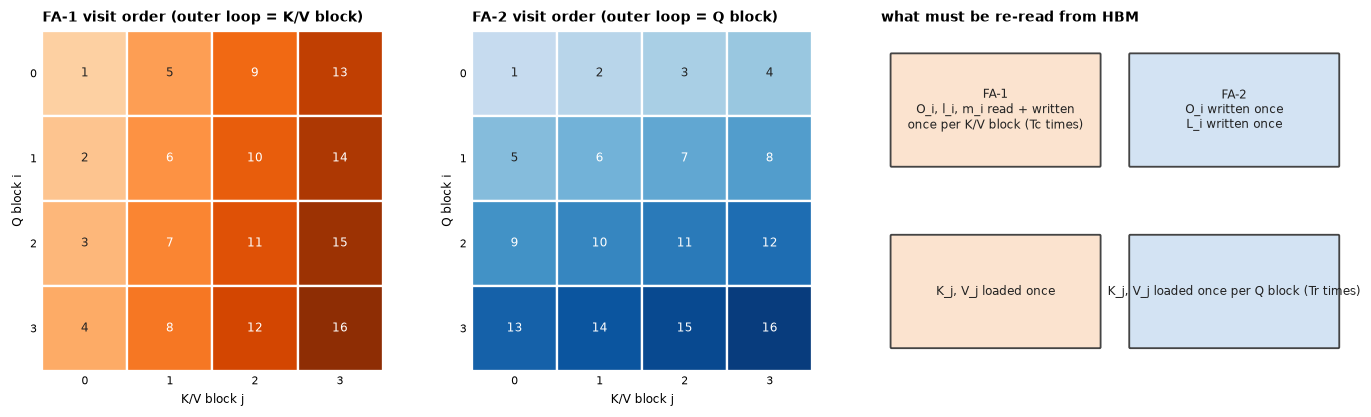

<sub>**Figure.** Left and middle: the same 16 tiles in a different order. In FA-1 (left) consecutive tiles share a K/V block; in FA-2 (middle) consecutive tiles share a Q block, so O_i can stay in registers across a whole row of 4. Right: the swap trades O/l/m traffic for K/V traffic. Notice that nothing is eliminated: FA-2 re-reads K and V, which is why the net IO change depends on block sizes (next cell).</sub>

In [6]:
nr = nc = 4
o1 = {(i, j): j*nr + i + 1 for i in range(nr) for j in range(nc)}      # FA-1: column-major (outer = K/V)
o2 = {(i, j): i*nc + j + 1 for i in range(nr) for j in range(nc)}      # FA-2: row-major (outer = Q)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
tile_grid(axs[0], nr, nc, order=o1, title="FA-1 visit order (outer loop = K/V block)", cmap="Oranges")
tile_grid(axs[1], nr, nc, order=o2, title="FA-2 visit order (outer loop = Q block)", cmap="Blues")
ax = axs[2]; ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.set_title("what must be re-read from HBM", loc="left", fontsize=9)
box(ax, .2, 3.6, 4.4, 2.0, "FA-1\nO_i, l_i, m_i read + written\nonce per K/V block (Tc times)", "#FBE3CF", fs=8)
box(ax, 5.2, 3.6, 4.4, 2.0, "FA-2\nO_i written once\nL_i written once", "#D3E3F3", fs=8)
box(ax, .2, .4, 4.4, 2.0, "K_j, V_j loaded once", "#FBE3CF", fs=8); box(ax, 5.2, .4, 4.4, 2.0, "K_j, V_j loaded once per Q block (Tr times)", "#D3E3F3", fs=8)
plt.tight_layout(); plt.show()
caption("Left and middle: the same 16 tiles in a different order. In FA-1 (left) consecutive tiles share a K/V block; in FA-2 (middle) consecutive tiles share a Q block, so O_i can stay in registers across a whole row of 4. Right: the swap trades O/l/m traffic for K/V traffic. Notice that nothing is eliminated: FA-2 re-reads K and V, which is why the net IO change depends on block sizes (next cell).")

**General definition.** With $T_r=\lceil N/B_r\rceil$ and $T_c=\lceil N/B_c\rceil$:

$$\text{IO}_{\text{FA-1}}=2Nd+T_c(3Nd+4N),\qquad \text{IO}_{\text{FA-2}}=Nd+Nd+N+T_r\cdot 2Nd .$$

FA-1 re-reads the $Q,O$ blocks $T_c$ times; FA-2 re-reads $K,V$ $T_r$ times. Which is smaller depends on $B_r$ vs $B_c$ and on how much SRAM each design needs. We verify the formulas against our counted loops, then compare at a fixed SRAM budget.

SRAM budget M=32768, d=64:  FA-1 blocks Br=64, Bc=128   FA-2 blocks Br=128, Bc=64
SRAM use FA-2 = Br*(2d+Bc) + 2*Bc*d = 32768 <= 32768


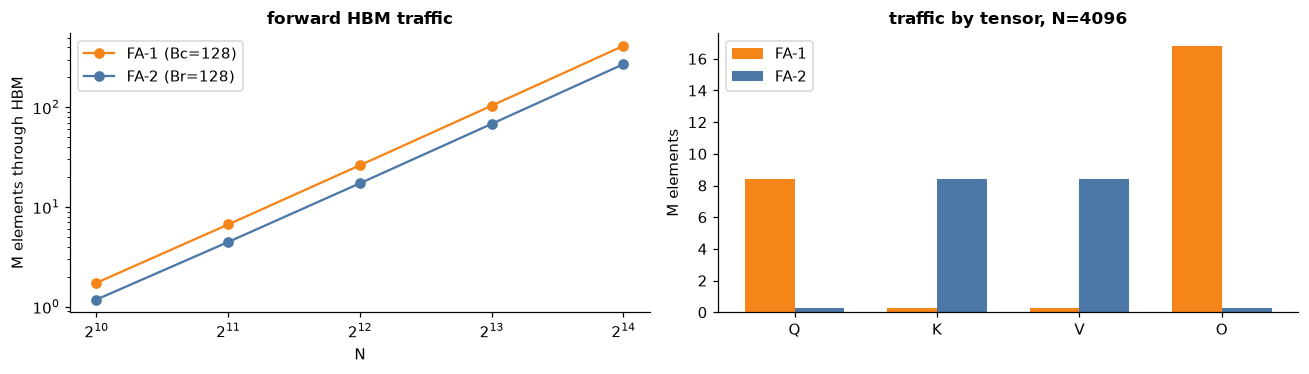

<sub>**Figure.** Left: at the same SRAM budget FA-2 moves less data than FA-1, but only by a modest constant factor. Right: the composition changes completely. FA-1's traffic is Q and O being re-streamed; FA-2's is K and V being re-streamed, while O is written exactly once. Notice that the swap is not primarily an IO win; its payoff is in the next section.</sub>

N=4096: FA-1 26.2 M, FA-2 17.3 M -> FA-2 / FA-1 = 0.66


True

In [7]:
def io_f1(N, d, Br, Bc): return 2*N*d + math.ceil(N/Bc) * (3*N*d + 4*N)
def io_f2(N, d, Br, Bc): return 2*N*d + N + math.ceil(N/Br) * 2*N*d
for (N_, d_, Br_, Bc_) in [(256, 32, 64, 64), (512, 64, 128, 64), (1024, 64, 128, 128)]:
    x_ = torch.randn(N_, d_); i1, i2 = IOCounter(), IOCounter(); flash1_forward(x_, x_, x_, Br_, Bc_, io=i1); flash2_forward(x_, x_, x_, Br_, Bc_, io=i2)
    check(f"IO formulas match counted IO (N={N_}, d={d_}, Br={Br_}, Bc={Bc_})", i1.total == io_f1(N_, d_, Br_, Bc_) and i2.total == io_f2(N_, d_, Br_, Bc_), f"FA1 {i1.total}  FA2 {i2.total}")
M, d = 32768, 64
Bc1 = math.ceil(M / (4*d)); Br1 = min(Bc1, d)                     # FA-1 rule from notebook 1
Bc2 = 64; Br2 = max(16, int((M - 2*Bc2*d) // (2*d + Bc2)) // 16 * 16)   # FA-2: Qi + Oi + S tile + Kj,Vj <= M
print(f"SRAM budget M={M}, d={d}:  FA-1 blocks Br={Br1}, Bc={Bc1}   FA-2 blocks Br={Br2}, Bc={Bc2}")
print(f"SRAM use FA-2 = Br*(2d+Bc) + 2*Bc*d = {Br2*(2*d+Bc2) + 2*Bc2*d} <= {M}")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
Ns = np.array([1024, 2048, 4096, 8192, 16384])
axs[0].plot(Ns, [io_f1(n, d, Br1, Bc1)/1e6 for n in Ns], "o-", color=COL["k"], label=f"FA-1 (Bc={Bc1})"); axs[0].plot(Ns, [io_f2(n, d, Br2, Bc2)/1e6 for n in Ns], "o-", color=COL["q"], label=f"FA-2 (Br={Br2})")
axs[0].set_xscale("log", base=2); axs[0].set_yscale("log"); axs[0].set_xlabel("N"); axs[0].set_ylabel("M elements through HBM"); axs[0].legend(); axs[0].set_title("forward HBM traffic")
n4 = 4096; i1, i2 = IOCounter(), IOCounter(); xx = torch.randn(n4, d); flash1_forward(xx, xx, xx, Br1, Bc1, io=i1); flash2_forward(xx, xx, xx, Br2, Bc2, io=i2)
ts = ["Q", "K", "V", "O"]; w = .35
axs[1].bar(np.arange(4) - w/2, [i1.by_tensor()[t]/1e6 for t in ts], w, color=COL["k"], label="FA-1"); axs[1].bar(np.arange(4) + w/2, [i2.by_tensor()[t]/1e6 for t in ts], w, color=COL["q"], label="FA-2")
axs[1].set_xticks(range(4)); axs[1].set_xticklabels(ts); axs[1].set_ylabel("M elements"); axs[1].legend(); axs[1].set_title("traffic by tensor, N=4096")
plt.tight_layout(); plt.show()
caption("Left: at the same SRAM budget FA-2 moves less data than FA-1, but only by a modest constant factor. Right: the composition changes completely. FA-1's traffic is Q and O being re-streamed; FA-2's is K and V being re-streamed, while O is written exactly once. Notice that the swap is not primarily an IO win; its payoff is in the next section.")
HEADLINE["io_f1"], HEADLINE["io_f2"] = i1.total, i2.total
print(f"N=4096: FA-1 {i1.total/1e6:.1f} M, FA-2 {i2.total/1e6:.1f} M -> FA-2 / FA-1 = {i2.total/i1.total:.2f}")
check("FA-2 writes O exactly once (N*d elements)", i2.writes["O"] == n4 * d)

In our model the traffic changes by a modest factor, so the swap is not what makes FA-2 faster by itself. What it does is make every Q block an *independent* unit of work.

## 4. Parallelism over the sequence

**A tiny example.** An A100 has 108 streaming multiprocessors (SMs, recalled from the spec). Suppose we run 1 sequence with 16 heads at $N=4096$. If one thread block handles one (batch, head), there are $16$ thread blocks and $92$ SMs are idle. If one thread block handles one (batch, head, Q-block), there are $16\times 32=512$ of them for $B_r=128$.

**General definition (our scheduling model).** Let $W$ be the number of equal-cost work items. They run in waves of $S$ SMs, so the time is $\lceil W/S\rceil$ units and the utilisation is $W/(S\lceil W/S\rceil)$. This ignores that several thread blocks can share an SM, so it is a *model* of occupancy, not a measurement.

batch*heads      N | FA-1 items util | FA-2 items util
          1   4096 |         1     1% |        32    30%
          8   4096 |         8     7% |       256    79%
         16   4096 |        16    15% |       512    95%
         64   4096 |        64    59% |      2048   100%
        108   4096 |       108   100% |      3456   100%


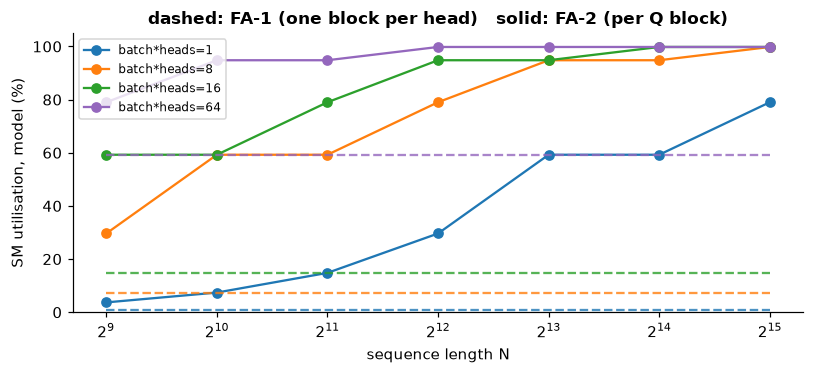

<sub>**Figure.** Dashed lines are flat because FA-1's work-item count does not grow with N. The solid FA-2 curves rise towards 100% as N grows, because the sequence supplies more independent items; the benefit is largest exactly when batch*heads is small, i.e. long-sequence, small-batch training and inference. Notice the sawtooth: utilisation dips whenever the item count is just above a multiple of 108 (a partial last wave).</sub>

True

In [8]:
S_SM = 108
def util(W, S=S_SM): return W / (S * math.ceil(W / S))
print(f"{'batch*heads':>11} {'N':>6} | FA-1 items util | FA-2 items util")
rows = []
for bh in (1, 8, 16, 64, 108):
    for N_ in (1024, 4096, 16384):
        w1, w2 = bh, bh * math.ceil(N_ / 128); rows.append((bh, N_, util(w1), util(w2)))
        if N_ == 4096: print(f"{bh:>11} {N_:>6} | {w1:>9} {util(w1)*100:>5.0f}% | {w2:>9} {util(w2)*100:>5.0f}%")
fig, ax = plt.subplots(figsize=(7.5, 3.5))
for bh, c in zip((1, 8, 16, 64), ("#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd")):
    Ns = np.array([512, 1024, 2048, 4096, 8192, 16384, 32768])
    ax.plot(Ns, [util(bh)*100]*len(Ns), "--", color=c, alpha=.8); ax.plot(Ns, [util(bh * math.ceil(n/128))*100 for n in Ns], "o-", color=c, label=f"batch*heads={bh}")
ax.set_xscale("log", base=2); ax.set_xlabel("sequence length N"); ax.set_ylabel("SM utilisation, model (%)"); ax.set_ylim(0, 105); ax.legend(fontsize=8); ax.set_title("dashed: FA-1 (one block per head)   solid: FA-2 (per Q block)")
plt.tight_layout(); plt.show()
caption("Dashed lines are flat because FA-1's work-item count does not grow with N. The solid FA-2 curves rise towards 100% as N grows, because the sequence supplies more independent items; the benefit is largest exactly when batch*heads is small, i.e. long-sequence, small-batch training and inference. Notice the sawtooth: utilisation dips whenever the item count is just above a multiple of 108 (a partial last wave).")
u1, u2 = util(16), util(16 * 32); HEADLINE["util"] = (u1, u2)
check("FA-2 occupancy model beats FA-1 at batch*heads=16, N=4096", u2 > u1 and u1 < 0.2, f"{u1*100:.0f}% -> {u2*100:.0f}%")

The cost of this change is that nothing is free in the other direction: the K/V re-reads (section 3) are now spread over many thread blocks that all pull the same $K,V$ from L2 cache or HBM. Causal masking changes the picture again, because it makes the work items *unequal*.

## 5. Causal masking: skipping tiles and balancing work

**A tiny example.** With $8\times8$ tiles and a causal mask, tile $(i,j)$ is entirely masked when $j>i$ (for square tiles). Those tiles can be skipped, not merely masked. Row block $i$ then has $i+1$ tiles of work: 1 for the first, 8 for the last.

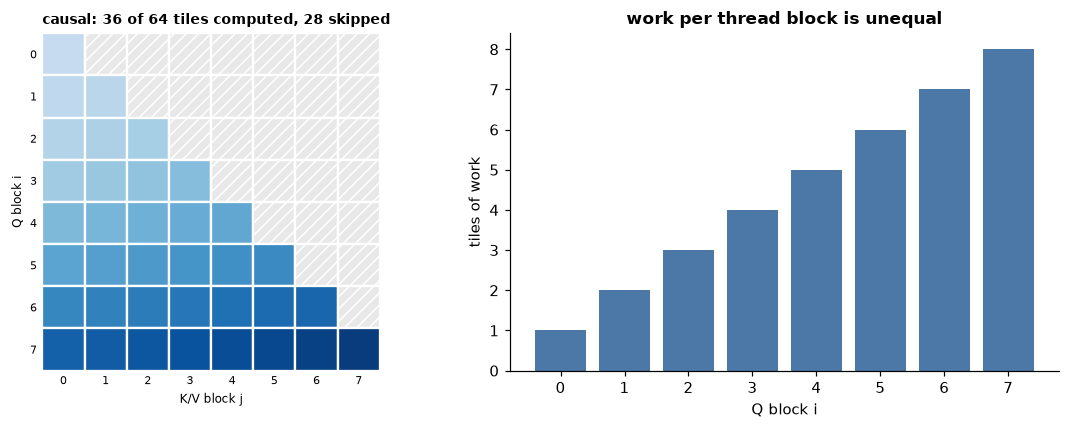

<sub>**Figure.** Left: hatched tiles are never loaded or multiplied. Right: the last row block does 8x the work of the first. Notice that if blocks run in index order on a limited number of SMs, the heavy ones start last and the tail of the schedule is a few SMs finishing long blocks alone.</sub>

causal matmul FLOPs / full = 0.5312   (expected tiles T(T+1)/2 / T^2 = 0.5312)


In [9]:
Tn = 8
live = [[j <= i for j in range(Tn)] for i in range(Tn)]
order = {}; s = 0
for i in range(Tn):
    for j in range(i + 1): s += 1; order[(i, j)] = s
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
tile_grid(axs[0], Tn, Tn, order=order, mask=live, label_order=False, title="causal: 36 of 64 tiles computed, 28 skipped", cmap="Blues")
work = [i + 1 for i in range(Tn)]; axs[1].bar(range(Tn), work, color=COL["q"]); axs[1].set_xlabel("Q block i"); axs[1].set_ylabel("tiles of work"); axs[1].set_title("work per thread block is unequal")
plt.tight_layout(); plt.show()
caption("Left: hatched tiles are never loaded or multiplied. Right: the last row block does 8x the work of the first. Notice that if blocks run in index order on a limited number of SMs, the heavy ones start last and the tail of the schedule is a few SMs finishing long blocks alone.")
N_, d_ = 1024, 64; xx = torch.randn(N_, d_); fa, fb = FlopCounter(), FlopCounter()
flash2_forward(xx, xx, xx, 64, 64, causal=False, fl=fa); flash2_forward(xx, xx, xx, 64, 64, causal=True, fl=fb)
Tn_ = N_ // 64; expect = Tn_ * (Tn_ + 1) / 2 / (Tn_ * Tn_)
print(f"causal matmul FLOPs / full = {fb.matmul/fa.matmul:.4f}   (expected tiles T(T+1)/2 / T^2 = {expect:.4f})")
check("causal tile skipping does exactly T(T+1)/2 of T^2 tiles", abs(fb.matmul / fa.matmul - expect) < 1e-9)
HEADLINE["causal_frac"] = fb.matmul / fa.matmul

**Scheduling model.** We simulate list scheduling of the causal row blocks of 16 heads onto 108 SMs (identical SMs, one item per SM at a time), comparing index order with "heaviest first". This is our own simulation of the idea, not a statement about what any particular kernel does.

In [10]:
import heapq
def makespan(costs, S):
    h = [0.0] * S; heapq.heapify(h)
    for c in costs: heapq.heappush(h, heapq.heappop(h) + c)
    return max(h)
Tn_, heads, S = 32, 16, 108                       # 32 row blocks (N=4096, Br=128), 16 heads
items = [i + 1 for _ in range(heads) for i in range(Tn_)]              # cost = tiles in the row block
asc, desc = makespan(items, S), makespan(sorted(items, reverse=True), S)
lower = max(sum(items) / S, max(items))
print(f"total work {sum(items)} tile-units, ideal (perfect balance) {sum(items)/S:.1f}, longest item {max(items)}")
print(f"index order makespan {asc:.0f}  |  heaviest-first makespan {desc:.0f}  |  lower bound {lower:.1f}")
print(f"heaviest-first is {asc/desc:.2f}x shorter than index order in this model")
check("heaviest-first scheduling is no worse than index order", desc <= asc)
check("both schedules respect the lower bound", desc >= lower - 1e-9 and asc >= lower - 1e-9)

total work 8448 tile-units, ideal (perfect balance) 78.2, longest item 32
index order makespan 98  |  heaviest-first makespan 80  |  lower bound 78.2
heaviest-first is 1.23x shorter than index order in this model


True

We found that tile skipping leaves exactly $136/256=53.1\%$ of the matmul work at $16\times16$ tiles (a 46.9% saving, tending to 50% as the tile count grows), and that ordering by cost shortens the modelled schedule. Both are independent of the arithmetic inside a tile. Inside a tile there is a third change, which concerns how four warps (groups of 32 GPU threads) divide the tile.

## 6. Splitting work between warps

**A tiny example.** A thread block has 4 warps and a $B_r\times B_c$ score tile. FA-1 splits **K** across warps ("split-K"): warp $w$ computes $S_w=Q_iK_{j,w}^\top$ for its quarter of the columns, and then the four partial outputs $P_wV_{j,w}$ must be **summed across warps**, which means writing them to shared memory, synchronising, and reading them back. FA-2 splits **Q** across warps ("split-Q"): warp $w$ owns $B_r/4$ rows, sees all columns, and its output rows are final with no cross-warp sum.

In [11]:
Br_, Bc_, d_, W = 8, 8, 4, 4
Qi, Kj, Vj = (torch.randn(n, d_, dtype=torch.float64) for n in (Br_, Bc_, Bc_)); sc = 1 / math.sqrt(d_)
def tile_full(Qi, Kj, Vj):
    S = Qi @ Kj.T * sc; m = S.max(1).values; P = torch.exp(S - m[:, None]); return m, P.sum(1), P @ Vj
def tile_split_k(Qi, Kj, Vj, W):
    parts = []
    for w in range(W):                                   # each warp: a slice of K/V columns, ALL rows
        sl = slice(w * Bc_ // W, (w + 1) * Bc_ // W); parts.append(tile_full(Qi, Kj[sl], Vj[sl]))
    m = torch.stack([p[0] for p in parts]).max(0).values                      # cross-warp reduction (shared mem + sync)
    l = sum(p[1] * torch.exp(p[0] - m) for p in parts); o = sum(p[2] * torch.exp(p[0] - m)[:, None] for p in parts)
    return m, l, o
def tile_split_q(Qi, Kj, Vj, W):
    parts = []
    for w in range(W):                                   # each warp: a slice of Q rows, ALL columns -> no reduction
        sl = slice(w * Br_ // W, (w + 1) * Br_ // W); parts.append(tile_full(Qi[sl], Kj, Vj))
    return tuple(torch.cat([p[t] for p in parts]) for t in range(3))
ref = tile_full(Qi, Kj, Vj)
for name, fn in (("split-K (FA-1)", tile_split_k), ("split-Q (FA-2)", tile_split_q)):
    out = fn(Qi, Kj, Vj, W); e = max(max_err(a, b) for a, b in zip(out, ref)); print(f"{name}: max error vs single-warp tile = {e:.1e}")
    check(f"{name} gives the same tile result", e < 1e-12)

split-K (FA-1): max error vs single-warp tile = 8.9e-16
split-Q (FA-2): max error vs single-warp tile = 0.0e+00


**How it is implemented, and what it costs.** In our simplified shared-memory model (elements, not bytes; register-level reuse ignored):

* split-K: every warp reads all of $Q_i$ (to multiply with its K slice), reads its K and V slice once, writes a partial $O$ plus $(m,\ell)$, then reads all partials back to reduce: $3\,W B_r d + 2 B_c d + \ldots$
* split-Q: each warp reads its slice of $Q_i$, but **all** of $K_j$ and $V_j$: $B_r d + 2\,W B_c d$, with no partial-output round trip.

Neither is free: split-Q reads K/V $W$ times, split-K reads Q $W$ times and pays a reduction. Which wins depends on the tile shape.

  Br   Bc | split-K  split-Q | ratio K/Q
  64  128 |   66560   69632 | 0.96
 128   64 |  108544   40960 | 2.65
 128  128 |  116736   73728 | 1.58
  64   64 |   58368   36864 | 1.58
 128   32 |  104448   24576 | 4.25
 256   64 |  208896   49152 | 4.25


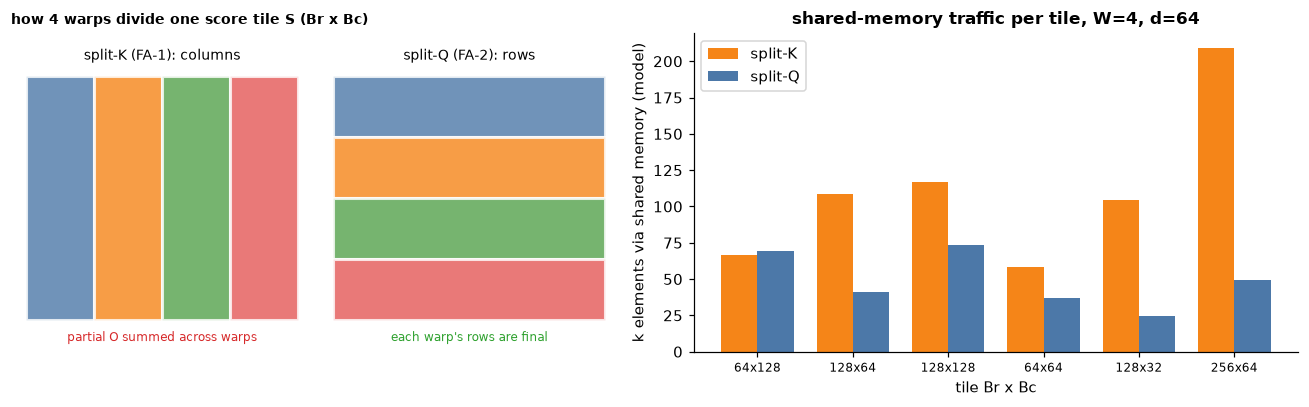

<sub>**Figure.** Left: same tile, two ways to cut it among warps. Right: in our model split-Q needs less shared-memory traffic whenever Bc is not much larger than Br (every config shown except 64x128, where split-K is about 4% cheaper), which is why FA-2 favours tall Q blocks. Notice that the model is sensitive to tile shape: it does not claim split-Q always wins.</sub>

True

In [12]:
def smem_split_k(Br, Bc, d, W): return W*Br*d + 2*Bc*d + 2*W*Br*(d + 2)           # Q read by each warp, K/V slices, write + read partials (O,m,l)
def smem_split_q(Br, Bc, d, W): return Br*d + 2*W*Bc*d
d, W = 64, 4
cfgs = [(64, 128), (128, 64), (128, 128), (64, 64), (128, 32), (256, 64)]
print(f"{'Br':>4} {'Bc':>4} | split-K  split-Q | ratio K/Q")
for Br, Bc in cfgs: print(f"{Br:>4} {Bc:>4} | {smem_split_k(Br,Bc,d,W):>7} {smem_split_q(Br,Bc,d,W):>7} | {smem_split_k(Br,Bc,d,W)/smem_split_q(Br,Bc,d,W):.2f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axs[0]; ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 6); ax.set_title("how 4 warps divide one score tile S (Br x Bc)", loc="left", fontsize=9)
cols = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
for w in range(4):
    ax.add_patch(plt.Rectangle((.3 + w * 1.35, .6), 1.35, 4.6, fc=cols[w], alpha=.8, ec="white", lw=2))
    ax.add_patch(plt.Rectangle((6.4, .6 + (3 - w) * 1.15), 5.4, 1.15, fc=cols[w], alpha=.8, ec="white", lw=2))
ax.text(3, 5.5, "split-K (FA-1): columns", ha="center", fontsize=9); ax.text(9.1, 5.5, "split-Q (FA-2): rows", ha="center", fontsize=9)
ax.text(3, .2, "partial O summed across warps", ha="center", fontsize=8, color=COL["bad"]); ax.text(9.1, .2, "each warp's rows are final", ha="center", fontsize=8, color=COL["good"])
ax = axs[1]; xs = np.arange(len(cfgs)); w_ = .38
ax.bar(xs - w_/2, [smem_split_k(a, b, d, W)/1e3 for a, b in cfgs], w_, color=COL["k"], label="split-K"); ax.bar(xs + w_/2, [smem_split_q(a, b, d, W)/1e3 for a, b in cfgs], w_, color=COL["q"], label="split-Q")
ax.set_xticks(xs); ax.set_xticklabels([f"{a}x{b}" for a, b in cfgs], fontsize=8); ax.set_xlabel("tile Br x Bc"); ax.set_ylabel("k elements via shared memory (model)"); ax.legend(); ax.set_title("shared-memory traffic per tile, W=4, d=64")
plt.tight_layout(); plt.show()
caption("Left: same tile, two ways to cut it among warps. Right: in our model split-Q needs less shared-memory traffic whenever Bc is not much larger than Br (every config shown except 64x128, where split-K is about 4% cheaper), which is why FA-2 favours tall Q blocks. Notice that the model is sensitive to tile shape: it does not claim split-Q always wins.")
check("split-Q reads less shared memory than split-K at 128x64", smem_split_q(128, 64, d, W) < smem_split_k(128, 64, d, W))

Now the same three ideas need to survive the backward pass.

## 7. The backward pass

FA-2's backward keeps the K/V block as the outer, *parallel* dimension (each thread block owns a $K_j,V_j$ pair and accumulates $dK_j,dV_j$ in SRAM) and adds into $dQ_i$ in HBM with atomic adds. It uses $L$ only, plus $D_i=dO_i\cdot O_i$. Because each $j$ is an independent work item, the *order* in which they run must not change the result beyond rounding. We implement it and test exactly that.

In [13]:
def flash2_backward(q, k, v, O, L, dO, Br, Bc, causal=False, j_order=None, io=None, fl=None):
    """Each K/V block j is an independent work item (one thread block). dQ is accumulated across items."""
    N, d = q.shape; sc = 1 / math.sqrt(d); io = io or IOCounter(); fl = fl or FlopCounter()
    dq, dk, dv = torch.zeros_like(q), torch.zeros_like(k), torch.zeros_like(v)
    D = (dO * O).sum(1); Tr, Tc = math.ceil(N / Br), math.ceil(N / Bc)
    for j in (j_order if j_order is not None else range(Tc)):
        js = slice(j*Bc, min((j+1)*Bc, N)); Kj, Vj = k[js], v[js]; dKj, dVj = torch.zeros_like(Kj), torch.zeros_like(Vj)
        i0 = (js.start // Br) if causal else 0                                   # first Q block that can see this K/V block
        for i in range(i0, Tr):
            is_ = slice(i*Br, min((i+1)*Br, N)); Qi, dOi = q[is_], dO[is_]
            S = Qi @ Kj.T * sc; fl.mm(len(Qi), len(Kj), d)
            if causal: S = S.masked_fill(torch.arange(js.start, js.stop)[None] > torch.arange(is_.start, is_.stop)[:, None], -float("inf"))
            P = torch.exp(S - L[is_][:, None]); dVj += P.T @ dOi; dP = dOi @ Vj.T
            dS = P * (dP - D[is_][:, None]) * sc; dq[is_] += dS @ Kj; io.read("dQ", Qi); io.write("dQ", Qi)   # atomic add on a GPU
            dKj += dS.T @ Qi; fl.mm(len(Kj), d, len(Qi)); fl.mm(len(Qi), len(Kj), d); fl.mm(len(Qi), d, len(Kj)); fl.mm(len(Kj), d, len(Qi))
        dk[js], dv[js] = dKj, dVj
    return dq, dk, dv

for causal_ in (False, True):
    N_, d_ = 192, 16
    q_, k_, v_ = (torch.randn(N_, d_, dtype=torch.float64, requires_grad=True) for _ in range(3)); dO_ = torch.randn(N_, d_, dtype=torch.float64)
    Oref, _ = ref_attention(q_, k_, v_, causal=causal_); Oref.backward(dO_)
    with torch.no_grad():
        O_, L_ = flash2_forward(q_, k_, v_, 32, 16, causal=causal_)
        g1 = flash2_backward(q_, k_, v_, O_, L_, dO_, 32, 16, causal=causal_)
        g2 = flash2_backward(q_, k_, v_, O_, L_, dO_, 32, 16, causal=causal_, j_order=torch.randperm(N_ // 16).tolist())
    e_ad = max(max_err(g, r.grad) for g, r in zip(g1, (q_, k_, v_))); e_ord = max(max_err(a, b) for a, b in zip(g1, g2))
    print(f"causal={causal_}: max |grad - autograd| = {e_ad:.1e};  max |order A - order B| = {e_ord:.1e}")
    check(f"FA-2 backward matches autograd (causal={causal_})", e_ad < 1e-11); check(f"FA-2 backward is independent of K/V block order (causal={causal_})", e_ord < 1e-12)

causal=False: max |grad - autograd| = 7.8e-16;  max |order A - order B| = 1.7e-16
causal=True: max |grad - autograd| = 2.7e-15;  max |order A - order B| = 2.2e-16


The backward pass matches autograd and is order-independent up to float64 rounding. In float32 on a GPU, atomic adds make the *order* of accumulation non-deterministic, so the gradient $dQ$ can differ in the last bits from run to run; we flag that as a cost of this parallelisation rather than a bug.

## 8. What we tried that did not work

We kept the following notes as failed variants rather than dropping them, because each one is a natural thing to try.

**Unnormalised accumulator in half precision.** Deferring the divide (section 2) means $\tilde O$ is a *sum of up to $N$ terms*, each up to $|v|$. In fp16 (max 65504) that can overflow even though the final normalised output is small. We simulate the worst case: uniform scores, positive values.

In [14]:
def accumulate(N, dtype, normalised, blk=128, vmean=1.0):
    o = torch.zeros((), dtype=dtype); l = torch.zeros((), dtype=torch.float32 if normalised else dtype)
    for _ in range(N // blk):
        p = torch.ones(blk, dtype=dtype); vals = torch.full((blk,), vmean, dtype=dtype)       # scores all equal -> exp(s-m)=1
        if normalised: l_new = l + p.sum().float(); o = ((l * o.float() + (p * vals).sum().float()) / l_new).to(dtype); l = l_new   # o stays bounded; l kept in fp32
        else: o = o + (p * vals).sum(); l = l + p.sum()
    return o.item() if normalised else (o / l).item()
for N_ in (8192, 65536, 131072):
    print(f"N={N_:>7}: fp16 unnormalised -> {accumulate(N_, torch.float16, False):>8}   fp16 o with fp32 l, normalised -> {accumulate(N_, torch.float16, True):.3f}   fp32 unnormalised -> {accumulate(N_, torch.float32, False):.3f}")
check("fp16 unnormalised accumulator breaks at N=131072 (l or o overflow)", not math.isfinite(accumulate(131072, torch.float16, False)) or abs(accumulate(131072, torch.float16, False) - 1.0) > 1e-2)
check("normalised o with fp32 l stays correct at N=131072", abs(accumulate(131072, torch.float16, True) - 1.0) < 1e-2)
check("fp32 unnormalised accumulator is fine at N=131072", abs(accumulate(131072, torch.float32, False) - 1.0) < 1e-4)

N=   8192: fp16 unnormalised ->      1.0   fp16 o with fp32 l, normalised -> 1.000   fp32 unnormalised -> 1.000
N=  65536: fp16 unnormalised ->      nan   fp16 o with fp32 l, normalised -> 1.000   fp32 unnormalised -> 1.000
N= 131072: fp16 unnormalised ->      nan   fp16 o with fp32 l, normalised -> 1.000   fp32 unnormalised -> 1.000


True

*Symptom:* the output is `nan` or wrong once $N\cdot|v|$ exceeds the fp16 range. *Root cause:* the running sums $\tilde o$ and $\ell$ grow linearly in $N$ (in the simulation even $\ell$ alone exceeds 65504 once $N>65504$), whereas a normalised $o$ stays bounded as long as $\ell$ is kept wide. *What we do instead:* keep $\tilde O$, $m$, $\ell$ in fp32 and cast only the final $O$ (this is also how the fused kernels keep them in practice, as far as we know from the public implementations; we have not re-read their code for this notebook).

**Bigger tiles are not free.** The $B_r$ that maximises reuse is bounded by SRAM. We scan the feasible region under our SRAM model.

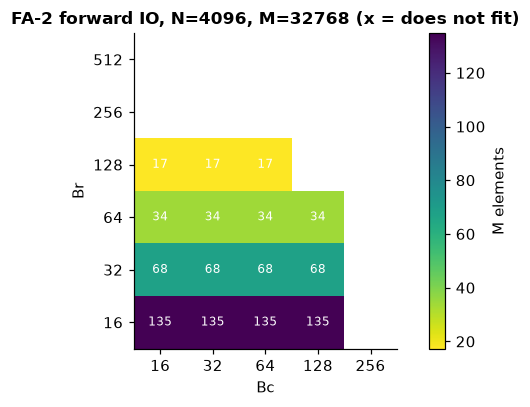

<sub>**Figure.** IO falls as Br grows (K/V are re-read fewer times) and does not depend on Bc in this model; the x cells are tiles whose Q, O, K, V and S do not all fit in SRAM. Notice that the best IO is at Br=128, the largest Br for which any Bc fits (Br=256 is infeasible for every Bc), so more SRAM, not cleverer tiling, is what buys further reduction.</sub>

best feasible IO: 17.3056 M elements


In [15]:
M, d = 32768, 64
Brs, Bcs = [16, 32, 64, 128, 256, 512], [16, 32, 64, 128, 256]
grid = np.full((len(Brs), len(Bcs)), np.nan)
for a, Br in enumerate(Brs):
    for b, Bc in enumerate(Bcs):
        if Br*(2*d + Bc) + 2*Bc*d <= M: grid[a, b] = io_f2(4096, d, Br, Bc) / 1e6
fig, ax = plt.subplots(figsize=(6.2, 3.8)); im = ax.imshow(grid, cmap="viridis_r", origin="lower")
ax.set_xticks(range(len(Bcs))); ax.set_xticklabels(Bcs); ax.set_yticks(range(len(Brs))); ax.set_yticklabels(Brs); ax.set_xlabel("Bc"); ax.set_ylabel("Br"); plt.colorbar(im, label="M elements")
for a in range(len(Brs)):
    for b in range(len(Bcs)): ax.text(b, a, "x" if np.isnan(grid[a, b]) else f"{grid[a,b]:.0f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title(f"FA-2 forward IO, N=4096, M={M} (x = does not fit)")
plt.tight_layout(); plt.show()
caption("IO falls as Br grows (K/V are re-read fewer times) and does not depend on Bc in this model; the x cells are tiles whose Q, O, K, V and S do not all fit in SRAM. Notice that the best IO is at Br=128, the largest Br for which any Bc fits (Br=256 is infeasible for every Bc), so more SRAM, not cleverer tiling, is what buys further reduction.")
best = np.nanmin(grid); bi = np.unravel_index(np.nanargmin(grid), grid.shape)
check("best IO is at the largest feasible Br (128); Br=256 has no feasible Bc", Brs[bi[0]] == 128 and np.isnan(grid[Brs.index(256)]).all())
print("best feasible IO:", best, "M elements")

Both are costs, not failures of correctness: the first shows where the extra precision budget goes, the second shows that tile choice is a constrained optimisation. Putting the measured pieces together:

In [16]:
u1, u2 = HEADLINE["util"]
display(Markdown(f"""
| quantity (N=4096, d=64 unless noted) | FA-1 | FA-2 | how obtained |
|---|---|---|---|
| matmul FLOPs | {f1.matmul/1e9:.2f} G | {f2.matmul/1e9:.2f} G | counted, identical |
| non-matmul ops | {f1.nonmatmul/1e6:.1f} M | {f2.nonmatmul/1e6:.1f} M ({HEADLINE['nonmm_ratio']*100:.0f}%) | counted, our op-model |
| HBM traffic (M elements) | {HEADLINE['io_f1']/1e6:.1f} | {HEADLINE['io_f2']/1e6:.1f} | counted loops, M=32768 |
| SM utilisation, batch*heads=16 | {u1*100:.0f}% | {u2*100:.0f}% | scheduling model, 108 SMs |
| causal tiles computed | - | {HEADLINE['causal_frac']*100:.1f}% of full (T=16) | counted |
| end-to-end speedup | 1x | ~2x | *reported* in Dao (2023), not measured here |
"""))


| quantity (N=4096, d=64 unless noted) | FA-1 | FA-2 | how obtained |
|---|---|---|---|
| matmul FLOPs | 4.29 G | 4.29 G | counted, identical |
| non-matmul ops | 92.8 M | 85.2 M (92%) | counted, our op-model |
| HBM traffic (M elements) | 26.2 | 17.3 | counted loops, M=32768 |
| SM utilisation, batch*heads=16 | 15% | 95% | scheduling model, 108 SMs |
| causal tiles computed | - | 53.1% of full (T=16) | counted |
| end-to-end speedup | 1x | ~2x | *reported* in Dao (2023), not measured here |


## 9. Closing thoughts

FlashAttention-2 is mostly a re-organisation: the arithmetic per tile is unchanged (identical matmul FLOPs in our count), and the gains come from doing less scalar work, exposing more independent work items, and avoiding cross-warp reductions. In our measurements the IO change is small, the non-matmul reduction is only 8% in our op-model, and the occupancy improvement is large precisely when the batch is small. That is consistent with the paper's framing but is not a speed measurement.

**Still open in this notebook.** We did not measure wall-clock time on any GPU; we did not model L2 caching of the re-read K/V; our shared-memory model ignores bank conflicts and register-level reuse; and the "heaviest-first" scheduling result is a toy simulation. FA-2 on Hopper GPUs also leaves performance unrealised (the paper reports it uses about 35% of H100 peak, recalled), which is the motivation for notebook 3.

Checks run in this notebook:

In [17]:
report()

PASS deferred normalisation gives the same value
PASS FA-2 forward exact: N=64 d=16 Br=8 Bc=8 causal=False   [err=8.9e-16]
PASS FA-2 forward exact: N=100 d=16 Br=16 Bc=32 causal=False   [err=8.9e-16]
PASS FA-2 forward exact: N=130 d=32 Br=64 Bc=32 causal=False   [err=8.9e-16]
PASS FA-2 forward exact: N=256 d=64 Br=128 Bc=64 causal=False   [err=8.9e-16]
PASS FA-2 forward exact: N=64 d=16 Br=8 Bc=8 causal=True   [err=8.9e-16]
PASS FA-2 forward exact: N=100 d=16 Br=32 Bc=16 causal=True   [err=8.9e-16]
PASS FA-2 forward exact: N=257 d=64 Br=128 Bc=64 causal=True   [err=1.0e-15]
PASS matmul FLOPs unchanged between FA-1 and FA-2
PASS FA-2 does fewer non-matmul ops than FA-1
PASS IO formulas match counted IO (N=256, d=32, Br=64, Bc=64)   [FA1 118784  FA2 82176]
PASS IO formulas match counted IO (N=512, d=64, Br=128, Bc=64)   [FA1 868352  FA2 328192]
PASS IO formulas match counted IO (N=1024, d=64, Br=128, Bc=128)   [FA1 1736704  FA2 1180672]
PASS FA-2 writes O exactly once (N*d elements)
PASS